# Trabajo Práctico N° 2: árboles de decisión, Bayes Ingenuo y k-NN

- Año: 2026
- Materia: Minería de Datos
- Integrantes: Frank, Maximiliano; Winter, Federico

Todas las particiones y todos los modelos usan random_state=63.

In [ ]:
# Instalo feature-engine para usar Winsorizer (en Colab no viene instalada)
!pip install feature-engine

In [1]:
# Importo las librerías y fijo la semilla
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from feature_engine.outliers import Winsorizer

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, KBinsDiscretizer
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (mean_absolute_error, mean_squared_error, accuracy_score,
                             precision_score, recall_score, classification_report, ConfusionMatrixDisplay)

SEED = 63  # random_state de todas las particiones y modelos


# Defino una función que agrega "Figura n" debajo del gráfico
def numerar(n):
    plt.tight_layout(rect=(0, 0.04, 1, 1))
    plt.figtext(0.5, 0.01, f"Figura {n}", ha="center", va="bottom")


# Defino una función que dibuja una matriz de correlación como mapa de calor, con título y número de figura
def plot_correlation_heatmap(corr, title, n):
    ax = sns.heatmap(corr, vmin=-1, vmax=1, center=0,
                     cmap=sns.diverging_palette(20, 220, n=200),
                     square=True, annot=True, annot_kws={'size': 8})
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment='right')
    plt.title(title)
    numerar(n)
    plt.show()


# Defino una función que arma una fila de la tabla de resultados (Precision macro, Recall macro y Accuracy)
def fila(particion, modelo, y, pred):
    return {"Partición": particion, "Modelo": modelo,
            "Precision macro": precision_score(y, pred, average="macro", zero_division=0),
            "Recall macro": recall_score(y, pred, average="macro", zero_division=0),
            "Accuracy": accuracy_score(y, pred)}


# Defino una función que dibuja una matriz de confusión por partición con los test de part_B (preds = {partición: predicciones})
def plot_cms(preds, titulo, n):
    fig, axes = plt.subplots(1, len(preds), figsize=(5.5 * len(preds), 4.8))
    for ax, (nombre, pred) in zip(axes, preds.items()):
        ConfusionMatrixDisplay.from_predictions(part_B[nombre][3], pred, ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"partición {nombre}")
    plt.suptitle(titulo)
    numerar(n)
    plt.show()


# Parte A: regresión (1000_Companies.csv)

## Descripción de las variables de 1000_Companies.csv

El conjunto tiene 1000 filas (una por empresa) y 5 columnas. La variable objetivo es Profit. El archivo no indica la unidad monetaria.

| Variable | Qué representa | Tipo | Rol |
|---|---|---|---|
| RyD_Spend | Gasto en investigación y desarrollo | Numérica continua | Predictora |
| Administration | Gasto en administración | Numérica continua | Predictora |
| MarketingSpend | Gasto en marketing | Numérica continua | Predictora |
| State | Estado donde opera la empresa (California, Florida o New York) | Categórica nominal | Predictora |
| Profit | Beneficio de la empresa | Numérica continua | Objetivo (regresión) |

## Actividad 1. Preparación de datos

Hacemos el EDA con el conjunto completo, limpiamos y después separamos en train y test. El codificador y el estandarizador se ajustan solo con train, para evitar fuga de datos.

In [2]:
# Leo el archivo y miro la estructura
df = pd.read_csv("1000_Companies.csv")
display(df.head())
df.info()

,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 39.2 KB


In [3]:
# Reviso nulos, duplicados, ceros y categorías
print("Columnas con nulos:", df.isna().any().sum())
print("Filas duplicadas:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])
print("\nCeros por columna numérica:")
print((df.select_dtypes("number") == 0).sum().to_string())
print("\nState:")
print(df["State"].value_counts().to_string())
df.describe()

Columnas con nulos: 0
Filas duplicadas: 1


,RyD_Spend,Administration,MarketingSpend,State,Profit
335,84533.0,122941.3141,231885.6935,California,121248.7116
755,84533.0,122941.3141,231885.6935,California,121248.7116



Ceros por columna numérica:
RyD_Spend         2
Administration    0
MarketingSpend    3
Profit            0

State:
State
California    344
New York      334
Florida       322


,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


Inspección: 1000 filas y 5 columnas, sin faltantes. Hay 1 fila duplicada (335 y 755). State está parejo (California 344, New York 334, Florida 322). RyD_Spend tiene 2 ceros y MarketingSpend 3. El máximo de Profit (476485) está lejos de su mediana (117641).

Hipótesis: Profit crece con RyD_Spend y MarketingSpend, Administration pesa poco, State influye poco y RyD_Spend y MarketingSpend están correlacionadas entre sí.

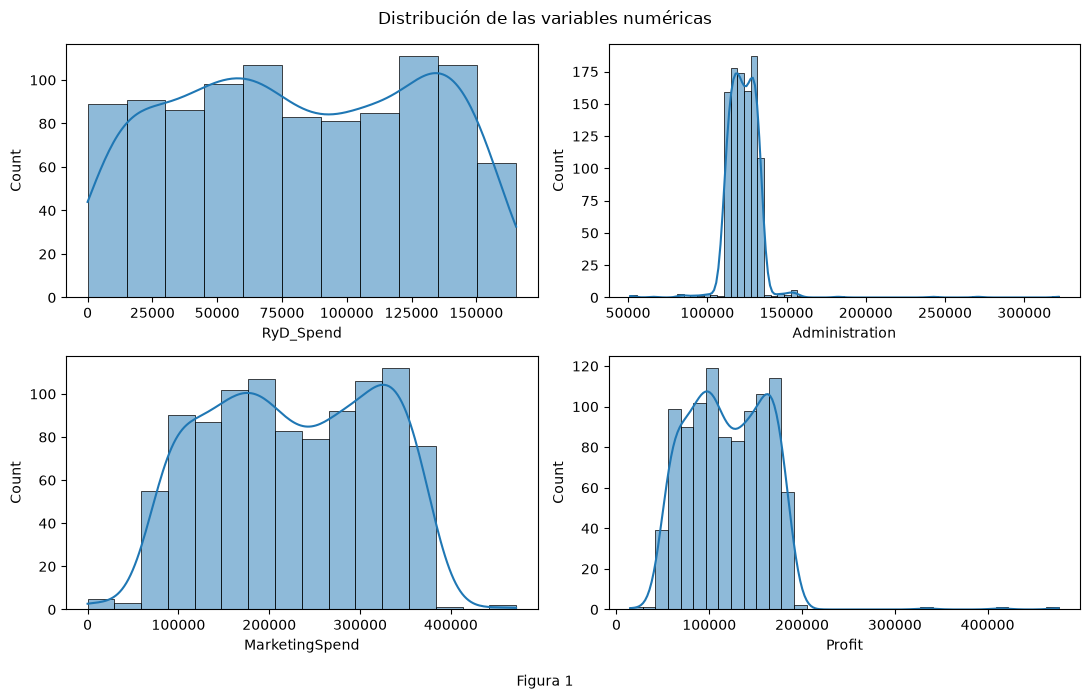

In [4]:
# Grafico la distribución de las variables numéricas
num_cols = ["RyD_Spend", "Administration", "MarketingSpend", "Profit"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, ax in zip(num_cols, axes.flatten()):
    sns.histplot(data=df, x=col, kde=True, edgecolor="black", linewidth=0.5, ax=ax)
plt.suptitle("Distribución de las variables numéricas")
numerar(1)
plt.show()

Figura 1. RyD_Spend va de 0 a 165349 y MarketingSpend de 0 a 471784. Administration se concentra entre 100000 y 150000, con valores aislados hasta 321652. Profit se concentra entre 40000 y 190000, con una cola hasta 476485. La cola de Profit y los valores aislados de Administration son candidatos a atípicos. La figura no prueba la hipótesis, que trata de relaciones entre variables.

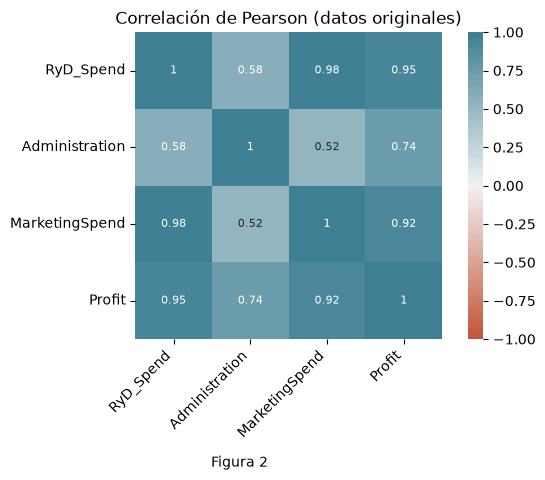

In [5]:
# Grafico la matriz de correlación
plot_correlation_heatmap(df[num_cols].corr(), "Correlación de Pearson (datos originales)", 2)

Figura 2. Profit tiene correlación de Pearson de 0.95 con RyD_Spend, 0.92 con MarketingSpend y 0.74 con Administration. RyD_Spend y MarketingSpend tienen 0.98 entre sí.

La hipótesis se cumple, salvo en Administration: su correlación es moderada y no débil. Como RyD_Spend y MarketingSpend aportan información casi igual, esperamos que el árbol use una de las dos en los primeros cortes.

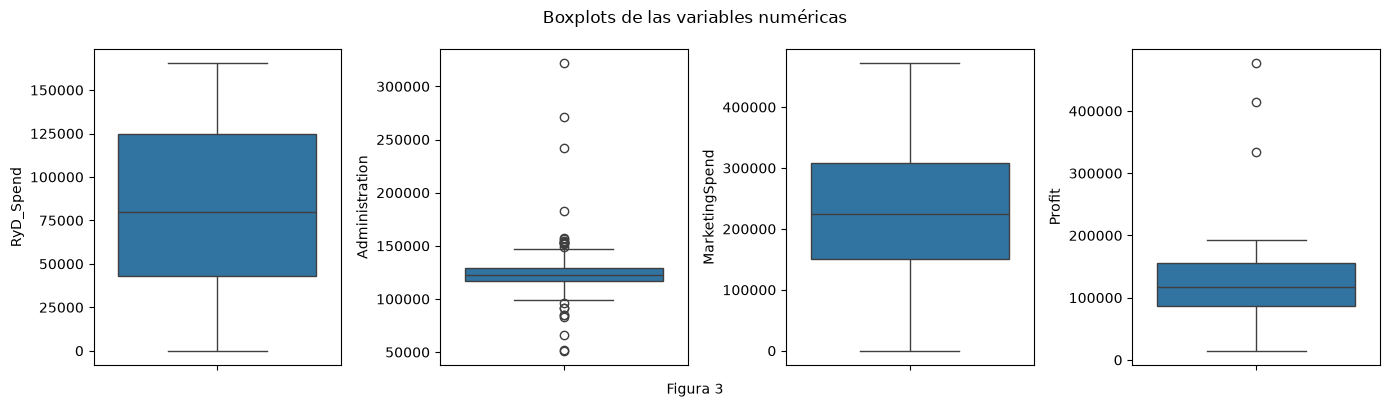

RyD_Spend: 0 atípicos (0.0%), límites [-79137, 246787]
Administration: 22 atípicos (2.2%), límites [97893, 147887]
MarketingSpend: 0 atípicos (0.0%), límites [-84861, 544020]
Profit: 3 atípicos (0.3%), límites [-18508, 260028]


In [6]:
# Grafico los boxplots y cuento los atípicos por IQR
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for col, ax in zip(num_cols, axes):
    sns.boxplot(y=df[col], ax=ax)
plt.suptitle("Boxplots de las variables numéricas")
numerar(3)
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, up = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[col] < low) | (df[col] > up)).sum()
    print(f"{col}: {n} atípicos ({n / len(df) * 100:.1f}%), límites [{low:.0f}, {up:.0f}]")

Figura 3. Por IQR hay 0 atípicos en RyD_Spend y MarketingSpend, 22 en Administration (2.2%) y 3 en Profit (0.3%). Antes de borrar, vemos si esas filas siguen la relación del resto.

,RyD_Spend,Administration,MarketingSpend,State,Profit
997,100275.47,241926.31,227142.82,California,413956.48
998,128456.23,321652.14,281692.32,California,333962.19
999,161181.72,270939.86,295442.17,New York,476485.43


Atípicos de Administration fuera de las 3 filas anómalas: 19, índice máximo 48
Profit de esas filas: 35673.0 a 191792.0


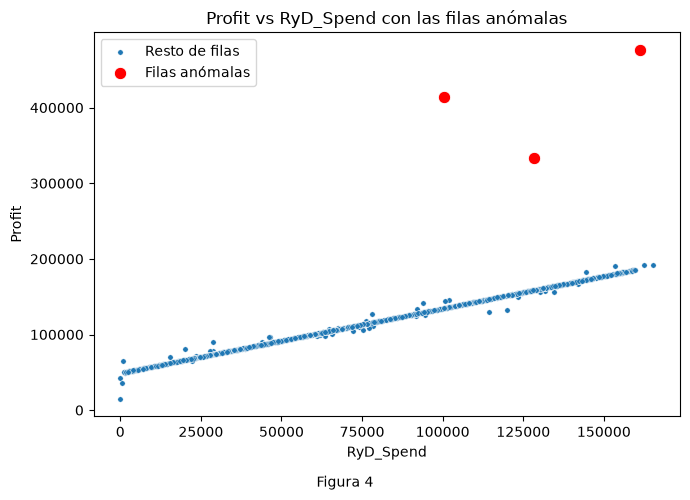

In [7]:
# Busco las filas con Profit fuera del límite IQR
q1, q3 = df["Profit"].quantile([0.25, 0.75])
anomalas = df[(df["Profit"] > q3 + 1.5 * (q3 - q1)) | (df["Profit"] < q1 - 1.5 * (q3 - q1))]
display(anomalas)

# Reviso si los atípicos de Administration siguen el comportamiento del resto antes de borrar
qa1, qa3 = df["Administration"].quantile([0.25, 0.75])
adm = df[((df["Administration"] > qa3 + 1.5 * (qa3 - qa1)) | (df["Administration"] < qa1 - 1.5 * (qa3 - qa1)))
         & ~df.index.isin(anomalas.index)]
print(f"Atípicos de Administration fuera de las 3 filas anómalas: {len(adm)}, índice máximo {adm.index.max()}")
print("Profit de esas filas:", adm["Profit"].min().round(0), "a", adm["Profit"].max().round(0))

# Grafico Profit vs RyD_Spend marcando las filas anómalas
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="RyD_Spend", y="Profit", s=15, ax=ax, label="Resto de filas")
sns.scatterplot(data=anomalas, x="RyD_Spend", y="Profit", color="red", s=80, ax=ax, label="Filas anómalas")
plt.title("Profit vs RyD_Spend con las filas anómalas")
numerar(4)
plt.show()

Figura 4. Profit sigue una recta casi perfecta con RyD_Spend. Las 3 filas rojas (997, 998 y 999) quedan muy por encima: Profit de 413956, 333962 y 476485, contra un máximo de 192262 en el resto, y Administration de 241926, 321652 y 270940. Son los únicos atípicos de Profit por IQR.

Los otros 19 atípicos de Administration están entre las primeras 50 filas (índice máximo 48) y tienen Profit entre 35673 y 191792. Siguen la relación con RyD_Spend.

In [8]:
# Elimino las 3 filas anómalas y la fila duplicada
df_clean = df.drop(index=anomalas.index).drop_duplicates()
print("Filas:", len(df), "->", len(df_clean))
print("Correlación de Pearson con Profit:")
print(pd.DataFrame({"original": df[num_cols].corr()["Profit"], "limpio": df_clean[num_cols].corr()["Profit"]}).round(3))
print("Máximos después de limpiar:")
print(df_clean[num_cols].max().to_string())

Filas: 1000 -> 996
Correlación de Pearson con Profit:
                original  limpio
RyD_Spend          0.945   0.999
Administration     0.742   0.745
MarketingSpend     0.917   0.981
Profit             1.000   1.000
Máximos después de limpiar:
RyD_Spend         165349.20
Administration    182645.56
MarketingSpend    471784.10
Profit            192261.83


Decisiones de limpieza:

- Eliminamos las 3 filas anómalas: no siguen la relación del resto (Figura 4).
- Conservamos los 19 atípicos de Administration: su Profit es coherente.
- Conservamos los ceros de RyD_Spend y MarketingSpend: son gastos posibles.
- Eliminamos la fila duplicada: con una copia en train y otra en test, el test incluiría un ejemplo ya visto.

Quedan 996 filas. La correlación de Profit con RyD_Spend sube de 0.945 a 0.999 y con MarketingSpend de 0.917 a 0.981. Con Administration casi no cambia (0.742 a 0.745).

In [9]:
# Separo variable objetivo de datos y obtengo las dos particiones con random_state=63
X = df_clean.drop(columns="Profit")
y = df_clean["Profit"]
particiones = {}
for nombre, ts in [("80/20", 0.2), ("70/30", 0.3)]:
    particiones[nombre] = train_test_split(X, y, test_size=ts, random_state=SEED)
    print(nombre, "-> train:", len(particiones[nombre][0]), "| test:", len(particiones[nombre][1]))

80/20

 -> train: 796 | test: 200
70/30 -> train: 697 | test: 299


In [10]:
# Codifico State con OneHotEncoder y estandarizo las numéricas con StandardScaler, ajustando solo con train
num_X = ["RyD_Spend", "Administration", "MarketingSpend"]
# Pongo State primero: RyD_Spend y MarketingSpend casi empatan como corte y el orden de columnas decide el desempate
prep = ColumnTransformer([("cat", OneHotEncoder(sparse_output=False), ["State"]),
                          ("num", StandardScaler(), num_X)],
                         verbose_feature_names_out=False).set_output(transform="pandas")

datos = {}
for nombre, (Xtrn, Xtst, ytrn, ytst) in particiones.items():
    datos[nombre] = (prep.fit_transform(Xtrn), prep.transform(Xtst))   # fit solo con train

# Compruebo las columnas resultantes en la partición 80/20
Xtrn_std, Xtst_std = datos["80/20"]
display(Xtrn_std.head())

,State_California,State_Florida,State_New York,RyD_Spend,Administration,MarketingSpend
398,1.0,0.0,0.0,-1.482993,-1.147181,-1.452454
794,1.0,0.0,0.0,-1.479694,-1.144655,-1.449217
102,0.0,1.0,0.0,1.015917,0.766041,0.999432
883,1.0,0.0,0.0,-0.351660,-0.281007,-0.342410
219,1.0,0.0,0.0,-1.518898,-1.174670,-1.487683


Particiones con random_state=63: el 80/20 deja 796 filas de train y 200 de test, y el 70/30 deja 697 y 299.

Decisiones de preparación:

- **State:** OneHotEncoder, porque sus tres categorías no tienen orden natural. Un código 0, 1, 2 impondría uno.
- **Numéricas:** StandardScaler, porque lo pide la consigna. Un árbol no lo necesita. Profit es el objetivo y no se transforma.
- **Ajuste solo con train:** si usáramos todos los datos, el test influiría en el preprocesamiento (fuga de datos).

Por eso los umbrales de las Figuras 5 y 6 están en unidades estandarizadas.

## Actividad 2. Árboles de decisión para regresión

Grilla: max_depth en 3, 5, 10; min_samples_split en 2, 5, 10; min_samples_leaf en 1, 5, 10 (27 combinaciones). Elegimos por validación cruzada de 5 folds sobre train, con el RMSE como criterio. El test no interviene en la elección.

Hipótesis: el primer corte será por RyD_Spend y MarketingSpend aparecerá después. Como la relación es casi lineal, esperamos un árbol de profundidad media.

In [11]:
# Defino la grilla de hiperparámetros; elijo con el RMSE, la misma métrica que reporto en test
# Uso validación cruzada de 5 folds sobre train, porque el TP solo define train y test
param_grid = {"max_depth": [3, 5, 10],
              "min_samples_split": [2, 5, 10],
              "min_samples_leaf": [1, 5, 10]}

grids_A = {}
for nombre in particiones:
    Xtrn, ytrn = datos[nombre][0], particiones[nombre][2]
    grids_A[nombre] = GridSearchCV(DecisionTreeRegressor(random_state=SEED), param_grid, cv=5,
                                   scoring="neg_root_mean_squared_error").fit(Xtrn, ytrn)
    g = grids_A[nombre]
    res = pd.DataFrame(g.cv_results_)
    res["RMSE (CV)"] = -res["mean_test_score"]
    print(f"Partición {nombre}: mejor = {g.best_params_}, profundidad real = {g.best_estimator_.get_depth()}, "
          f"hojas = {g.best_estimator_.get_n_leaves()}")
    display(res.sort_values("RMSE (CV)")[["param_max_depth", "param_min_samples_split", "param_min_samples_leaf",
                                         "RMSE (CV)"]].head(8).round(0))

Partición 80/20: mejor = {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}, profundidad real = 8, hojas = 130


,param_max_depth,param_min_samples_split,param_min_samples_leaf,RMSE (CV)
23,10,10,5,1824.0
21,10,2,5,1824.0
22,10,5,5,1824.0
24,10,2,10,2056.0
26,10,10,10,2056.0
25,10,5,10,2056.0
20,10,10,1,2195.0
18,10,2,1,2373.0


Partición 70/30: mejor = {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}, profundidad real = 8, hojas = 106


,param_max_depth,param_min_samples_split,param_min_samples_leaf,RMSE (CV)
23,10,10,5,2167.0
21,10,2,5,2167.0
22,10,5,5,2167.0
24,10,2,10,2305.0
26,10,10,10,2305.0
25,10,5,10,2305.0
14,5,10,5,2475.0
12,5,2,5,2475.0


En las dos particiones gana max_depth=10, min_samples_leaf=5 y min_samples_split=2. El RMSE de validación es 1824 (80/20) y 2167 (70/30). Hay 3 configuraciones empatadas en primer lugar: con min_samples_leaf=5, un nodo necesita al menos 10 observaciones para dividirse, por lo que min_samples_split=2, 5 y 10 dan el mismo árbol.

- max_depth: las mejores usan 10 (dos del 70/30 usan 5). max_depth=3 no aparece: subajusta.
- min_samples_leaf: con 5 el RMSE es el menor. Con 10 sube (2056 y 2305). Con 1 el árbol se ajusta al ruido (2195 y 2373 en el 80/20).

El árbol elegido tiene profundidad 8 y 130 hojas en el 80/20, y 106 hojas en el 70/30.

In [12]:
# Calculo MAE, MSE y RMSE sobre ambos conjuntos de test
preds_A, filas = {}, {}
for nombre, g in grids_A.items():
    ytst = particiones[nombre][3]
    preds_A[nombre] = g.predict(datos[nombre][1])   # predigo con el mejor árbol de GridSearchCV
    mse = mean_squared_error(ytst, preds_A[nombre])
    filas[nombre] = {"MAE": mean_absolute_error(ytst, preds_A[nombre]), "MSE": mse, "RMSE": np.sqrt(mse)}
tabla_A = pd.DataFrame(filas).T.rename_axis("Partición")
display(tabla_A.round(1))

,MAE,MSE,RMSE
Partición,,,
80/20,1098.9,12222722.2,3496.1
70/30,942.6,8579615.4,2929.1


Resultados en test:

- 80/20: MAE 1098.9, MSE 12222722.2 y RMSE 3496.1.
- 70/30: MAE 942.6, MSE 8579615.4 y RMSE 2929.1.

El MAE equivale a cerca del 1% de la mediana de Profit (117641). El RMSE es mayor que el MAE: hay pocos errores grandes. Los test son distintos (200 y 299 filas), así que la diferencia entre particiones no prueba que una sea mejor.

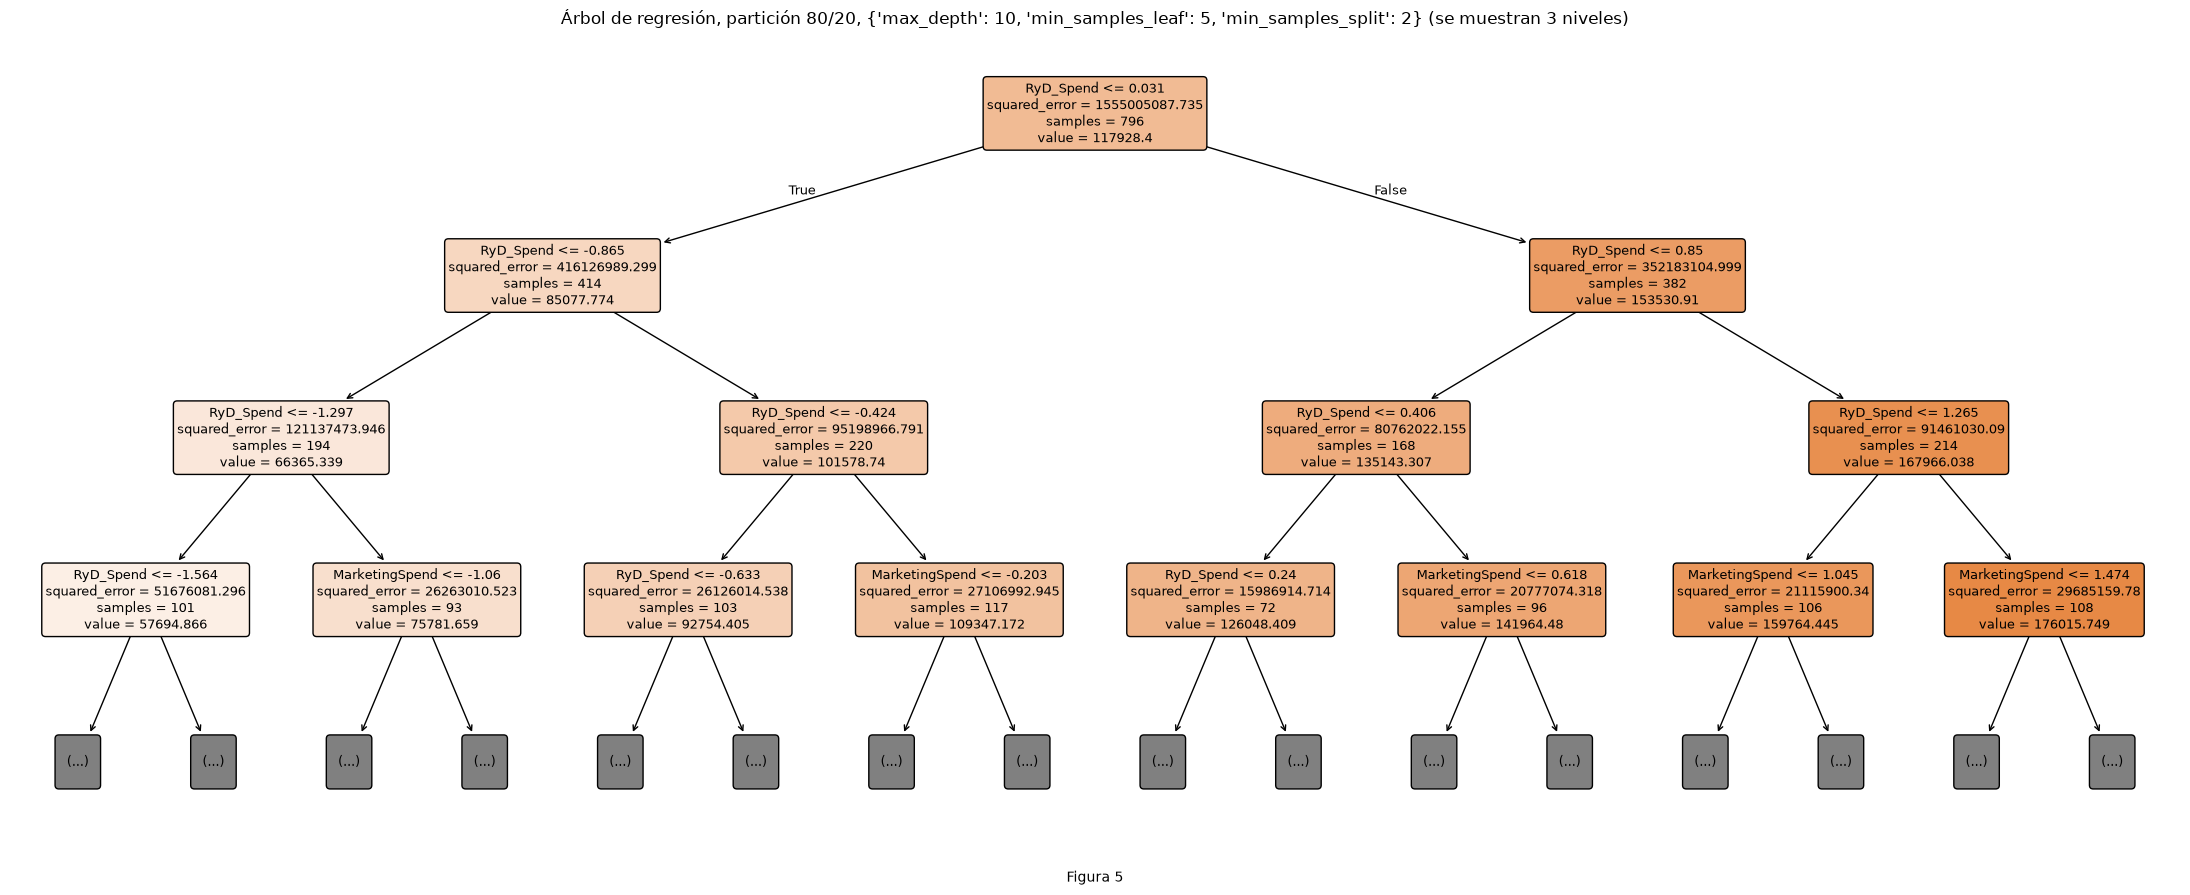

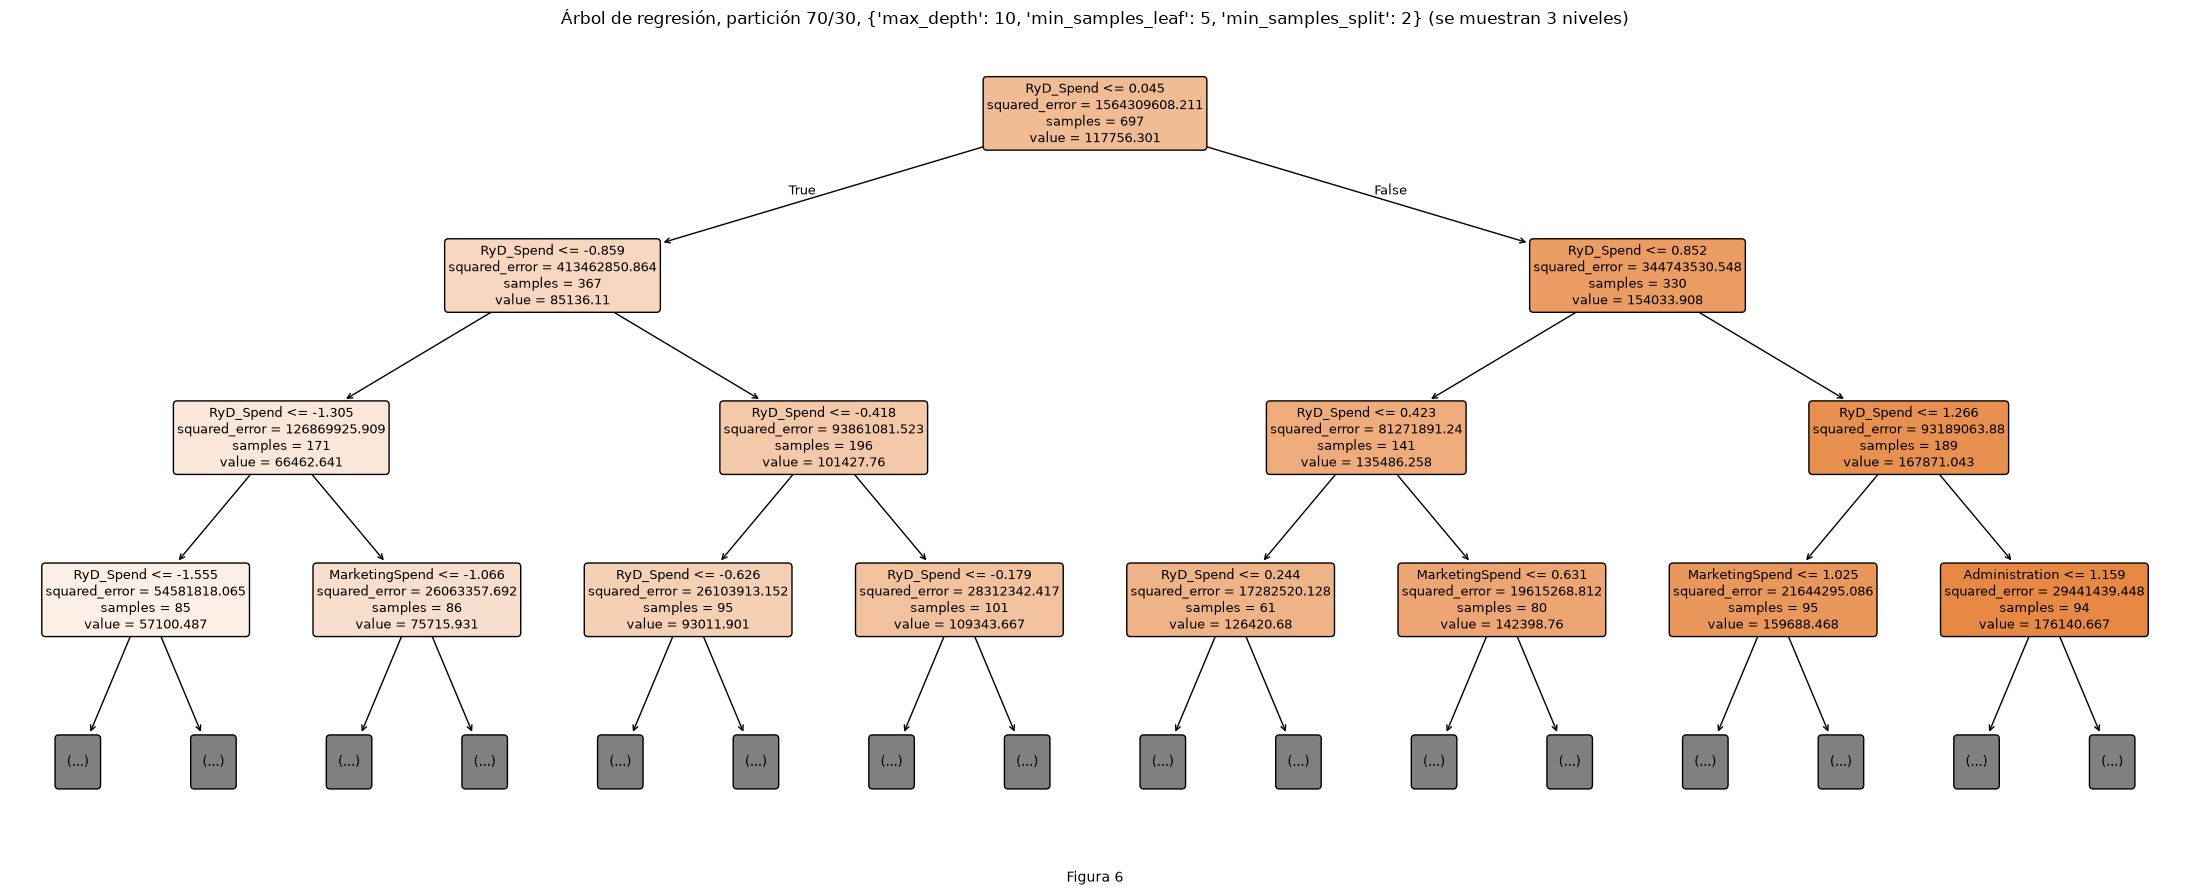

In [13]:
# Grafico cada árbol con plot_tree hasta max_depth=3 para que se lea
for i, (nombre, g) in enumerate(grids_A.items(), 1):
    plt.figure(figsize=(22, 9))
    plot_tree(g.best_estimator_, feature_names=list(datos[nombre][0].columns),
              filled=True, rounded=True, max_depth=3, fontsize=9)
    plt.title(f"Árbol de regresión, partición {nombre}, {g.best_params_} (se muestran 3 niveles)")
    numerar(4 + i)
    plt.show()

Figuras 5 y 6. Los umbrales están en desvíos respecto de la media de train. Graficamos hasta max_depth=3 porque los árboles completos tienen 130 y 106 hojas. La raíz divide por RyD_Spend en 0.031 (80/20) y 0.045 (70/30), que equivalen a 82150.5 y 82618. Los dos niveles siguientes también dividen por RyD_Spend. MarketingSpend aparece en el cuarto nivel de nodos, y Administration en un nodo del 70/30. State no aparece.

Coincide con la hipótesis: RyD_Spend es la más correlacionada (0.999) y MarketingSpend aparece después.

In [14]:
# Armo una tabla con la importancia de cada variable en el mejor árbol de cada partición
for nombre, g in grids_A.items():
    print(f"Partición {nombre}")
    display(pd.DataFrame({"features": datos[nombre][0].columns,
                          "importances": g.best_estimator_.feature_importances_})
            .sort_values(by="importances", ascending=False).round(4))

Partición 80/20


,features,importances
3,RyD_Spend,0.9892
5,MarketingSpend,0.0096
4,Administration,0.0012
2,State_New York,0.0000
0,State_California,0.0000
1,State_Florida,0.0000


Partición 70/30


,features,importances
3,RyD_Spend,0.9909
5,MarketingSpend,0.0058
4,Administration,0.0032
1,State_Florida,0.0000
0,State_California,0.0000
2,State_New York,0.0000


Importancias. En ambos árboles RyD_Spend concentra casi toda la importancia (0.989 en el 80/20 y 0.991 en el 70/30). MarketingSpend y Administration quedan por debajo de 0.01 cada una y las variables de State valen 0.0000. Confirma lo visto en las Figuras 5 y 6: State no aporta.

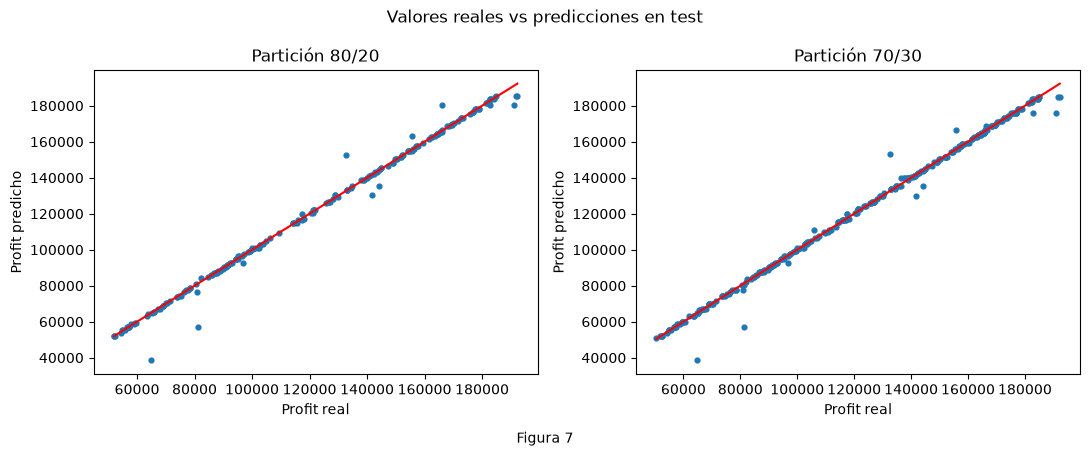

In [15]:
# Grafico los valores reales contra la predicción en test
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, nombre in zip(axes, grids_A):
    ytst = particiones[nombre][3]
    ax.scatter(ytst, preds_A[nombre], s=12)
    ax.plot([ytst.min(), ytst.max()], [ytst.min(), ytst.max()], color="red")
    ax.set_title(f"Partición {nombre}")
    ax.set_xlabel("Profit real")
    ax.set_ylabel("Profit predicho")
plt.suptitle("Valores reales vs predicciones en test")
numerar(7)
plt.show()

Figura 7. Los puntos se alinean sobre la diagonal en ambos test. Se separan unos pocos (por ejemplo, Profit real cerca de 65000 con predicción cerca de 39000): son los errores grandes que suben el RMSE. Es coherente con una relación casi lineal y un MAE bajo.

# Parte B: clasificación (drugType.csv)

## Descripción de las variables de drugType.csv

El conjunto tiene 200 filas (una por paciente) y 6 columnas. La variable objetivo es Droga, con 5 clases. No hay diccionario de datos: interpretamos las columnas por su nombre.

| Variable | Qué representa | Tipo | Rol |
|---|---|---|---|
| Edad | Edad del paciente, en años | Numérica discreta | Predictora |
| Sexo | Sexo del paciente (F o M) | Categórica nominal | Predictora |
| BP | Nivel de presión arterial (Bajo, Normal o Alto) | Categórica ordinal | Predictora |
| Colesterol | Nivel de colesterol (Normal o Alto) | Categórica ordinal | Predictora |
| Na_a_K | Relación entre sodio y potasio en sangre | Numérica continua | Predictora |
| Droga | Medicamento indicado (DrogaA, DrogaB, DrogaC, DrogaX o DrogaY) | Categórica nominal | Objetivo (clasificación) |

## Actividad 3. Preparación de datos

Seguimos el orden de los notebooks de la cátedra: inspección general con todo el conjunto, split estratificado y EDA solo con train (partición 80/20, 160 filas). Los transformadores se ajustan solo con train.

Hipótesis: Na_a_K separa mejor las clases, BP y Colesterol aportan reglas, Sexo no influye y las clases no están parejas.

In [16]:
# Leo el archivo y miro estructura, nulos, duplicados y descriptivas
dd = pd.read_csv("drugType.csv")
display(dd.head())
dd.info()
print("Columnas con nulos:", dd.isna().any().sum())
print("Filas duplicadas:", dd.duplicated().sum())
dd.describe()

,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB
Columnas con nulos: 0
Filas duplicadas: 0


,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


,Cantidad,Porcentaje
Droga,,
DrogaY,91,45.5
DrogaX,54,27.0
DrogaA,23,11.5
DrogaC,16,8.0
DrogaB,16,8.0


Razón clase mayoritaria / minoritaria: 5.69


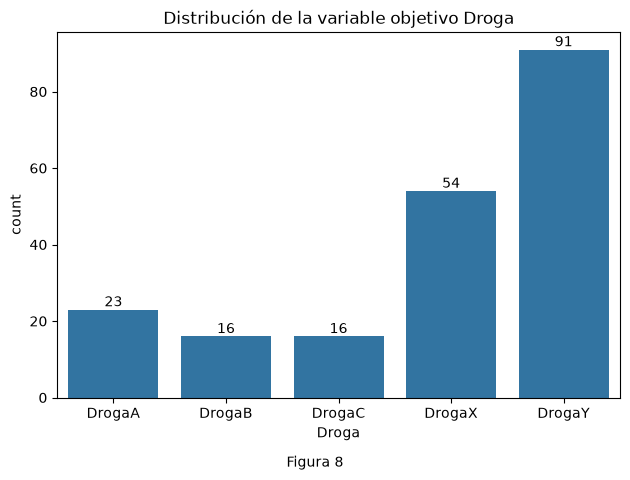

In [17]:
# Miro el balance de la variable objetivo Droga
cantidad = dd["Droga"].value_counts()
balance = pd.DataFrame({"Cantidad": cantidad, "Porcentaje": (cantidad / len(dd) * 100).round(1)})
display(balance)
print("Razón clase mayoritaria / minoritaria:", round(cantidad.max() / cantidad.min(), 2))

orden = sorted(dd["Droga"].unique())
ax = sns.countplot(data=dd, x="Droga", order=orden)
ax.bar_label(ax.containers[0])
plt.title("Distribución de la variable objetivo Droga")
numerar(8)
plt.show()

Inspección: 200 filas y 6 columnas, sin nulos ni duplicados. Edad va de 15 a 74 y Na_a_K de 6.27 a 38.25.

Figura 8. Hay desbalance: DrogaY tiene 91 casos (45.5%), DrogaX 54 (27.0%), DrogaA 23 (11.5%), DrogaB 16 (8.0%) y DrogaC 16 (8.0%). La clase mayoritaria es 5.69 veces la minoritaria. Responder siempre DrogaY da Accuracy de 0.455. La hipótesis se cumple.

Por eso estratificamos las particiones y evaluamos con Precision y Recall macro, junto con Accuracy. Para elegir hiperparámetros usamos F1 macro.

In [18]:
# Separo variable objetivo de datos y obtengo las dos particiones estratificadas
Xd = dd.drop(columns="Droga")
yd = dd["Droga"]
part_B = {}
for nombre, ts in [("80/20", 0.2), ("70/30", 0.3)]:
    part_B[nombre] = train_test_split(Xd, yd, test_size=ts, random_state=SEED, stratify=yd)
conteo = pd.concat({f"{n} {c}": pd.Series(part_B[n][i]).value_counts()
                    for n in part_B for c, i in [("train", 2), ("test", 3)]}, axis=1)
display(conteo)

# Trabajo el EDA con el train de la partición 80/20
Xtrn, Xtst, ytrn, ytst = part_B["80/20"]
train = pd.concat([Xtrn, ytrn], axis=1)

,80/20 train,80/20 test,70/30 train,70/30 test
Droga,,,,
DrogaY,73,18,64,27
DrogaX,43,11,38,16
DrogaA,18,5,16,7
DrogaC,13,3,11,5
DrogaB,13,3,11,5


Particiones estratificadas: el 80/20 deja 160 filas de train y 40 de test, y el 70/30 deja 140 y 60. Cada clase conserva su proporción. DrogaB queda con 13 casos en train y 3 en test (80/20), y con 11 y 5 (70/30). Con 3 a 5 casos de test en las clases chicas, un solo error pesa mucho en el Recall (un error en DrogaB con 3 casos lo baja a 0.67).

Desde acá el EDA usa el train del 80/20.

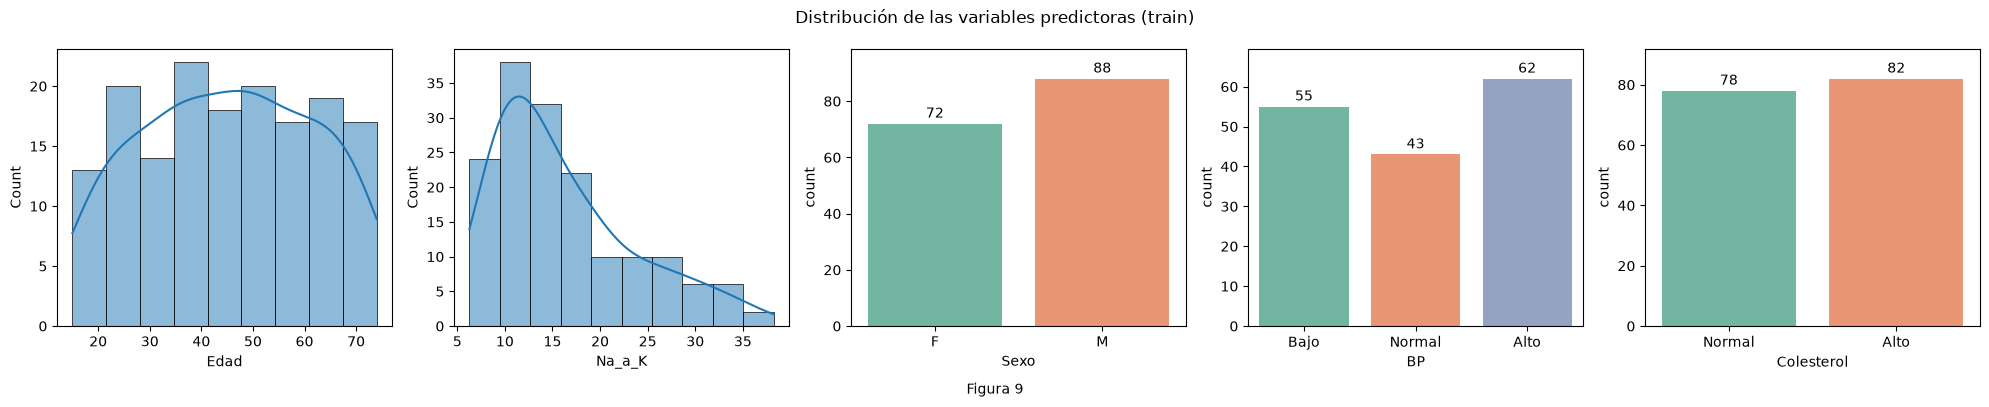

In [19]:
# Grafico la distribución de cada variable predictora en train
ordenes = {"Sexo": ["F", "M"], "BP": ["Bajo", "Normal", "Alto"], "Colesterol": ["Normal", "Alto"]}
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for col, ax in zip(["Edad", "Na_a_K"], axes[:2]):
    sns.histplot(data=train, x=col, kde=True, edgecolor="black", linewidth=0.5, ax=ax)
for (col, orden_c), ax in zip(ordenes.items(), axes[2:]):
    sns.countplot(data=train, x=col, order=orden_c, hue=col, hue_order=orden_c, palette="Set2", legend=False, ax=ax)
    for barras in ax.containers:
        ax.bar_label(barras, padding=2)
    ax.margins(y=0.12)
plt.suptitle("Distribución de las variables predictoras (train)")
numerar(9)
plt.show()

Figura 9 (train). Edad se reparte de forma pareja entre 15 y 74 años, con entre 13 y 22 casos por intervalo y sin un pico marcado. Na_a_K se concentra entre 6 y 19, con el máximo entre 9.5 y 12.7, y tiene una cola larga hasta 38.25. Las categóricas están parejas: Sexo (F 72 y M 88), BP (Bajo 55, Normal 43 y Alto 62) y Colesterol (Normal 78 y Alto 82). La figura describe cada variable por separado y no permite probar la hipótesis, que trata de la relación con Droga.

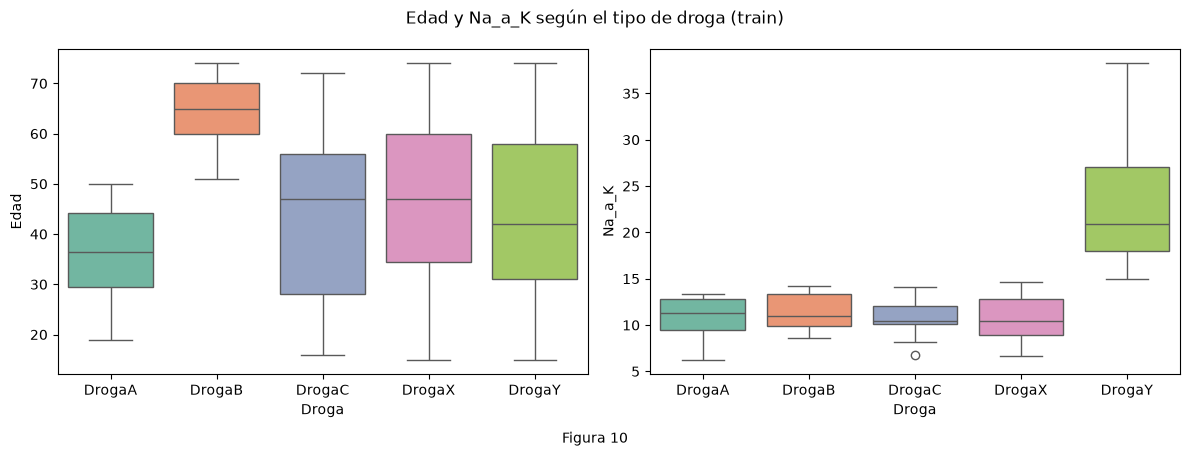

       Edad     Na_a_K       
        min max    min    max
Droga                        
DrogaA   19  50   6.27  13.31
DrogaB   51  74   8.62  14.24
DrogaC   16  72   6.77  14.16
DrogaX   15  74   6.68  14.64
DrogaY   15  74  15.02  38.25 

Droga   DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
BP                                            
Alto        18      13       0       0      31
Bajo         0       0      13      15      27
Normal       0       0       0      28      15 

Droga       DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Colesterol                                        
Alto            10       7      13      15      37
Normal           8       6       0      28      36 

Droga  DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Sexo                                         
F           7       4       6      20      35
M          11       9       7      23      38


In [20]:
# Grafico Edad y Na_a_K según el tipo de droga y cuento categorías por droga, en train
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for col, ax in zip(["Edad", "Na_a_K"], axes):
    sns.boxplot(data=train, x="Droga", y=col, order=orden, hue="Droga", hue_order=orden, palette="Set2", legend=False, ax=ax)
plt.suptitle("Edad y Na_a_K según el tipo de droga (train)")
numerar(10)
plt.show()

print(train.groupby("Droga")[["Edad", "Na_a_K"]].agg(["min", "max"]).round(2), "\n")
print(pd.crosstab(train["BP"], train["Droga"]), "\n")
print(pd.crosstab(train["Colesterol"], train["Droga"]), "\n")
print(pd.crosstab(train["Sexo"], train["Droga"]))

Figura 10 y tablas (train). En el boxplot de Na_a_K, DrogaY queda por encima de las otras cuatro clases (mediana 20.9 contra 10.4 a 11.3): sus valores van de 15.02 a 38.25 y los de las demás no superan 14.64. En el de Edad, DrogaB (mediana 65, de 51 a 74 años) y DrogaA (mediana 36.5, de 19 a 50) quedan separadas, y DrogaC, DrogaX y DrogaY cubren casi todo el rango, con medianas de 47, 47 y 42.

Las tablas muestran reglas por categoría. DrogaA y DrogaB aparecen solo con BP Alto (18 y 13 casos). DrogaC aparece solo con BP Bajo (13 casos) y solo con Colesterol Alto. DrogaX aparece con BP Bajo y Normal (15 y 28) y nunca con BP Alto. Sexo reparte cada clase de forma pareja (DrogaX tiene 20 F y 23 M).

La hipótesis se cumple: Na_a_K es la variable principal, BP y Colesterol aportan reglas y Sexo no influye. Edad, que no habíamos previsto, ayuda a distinguir DrogaA de DrogaB.

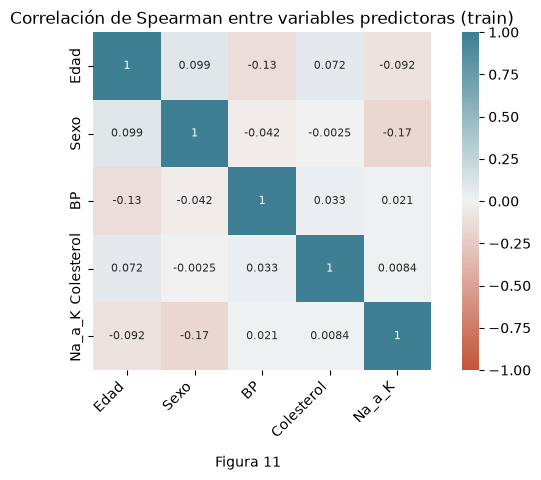

In [21]:
# Codifico las variables ordinales y calculo la correlación de Spearman en train
cat_cols = ["Sexo", "BP", "Colesterol"]
categorias = [["F", "M"], ["Bajo", "Normal", "Alto"], ["Normal", "Alto"]]  # orden natural de BP y Colesterol
dd_cod = Xtrn.copy()
dd_cod[cat_cols] = OrdinalEncoder(categories=categorias).fit_transform(dd_cod[cat_cols])
plot_correlation_heatmap(dd_cod.corr(method="spearman"), "Correlación de Spearman entre variables predictoras (train)", 11)

Figura 11 (train). Las correlaciones de Spearman entre predictoras tienen valor absoluto de 0.17 o menos. La mayor es la de Sexo con Na_a_K (-0.17). Las predictoras son casi independientes entre sí, lo que favorece a Bayes Ingenuo, que supone independencia entre atributos. Tampoco hay redundancia que eliminar para árboles y k-NN. Excluimos Droga de la matriz porque es nominal.

Codificación: Sexo (F, M), BP (Bajo, Normal, Alto) y Colesterol (Normal, Alto) se codifican con OrdinalEncoder y orden natural explícito.

In [22]:
# Cuento los atípicos por IQR en train y miro a qué clase pertenecen
for col in ["Edad", "Na_a_K"]:
    q1, q3 = train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (train[col] < q1 - 1.5 * iqr) | (train[col] > q3 + 1.5 * iqr)
    print(f"{col}: {mask.sum()} atípicos ({mask.mean() * 100:.1f}%)")
    if mask.sum():
        print("  Clases de los atípicos:", train.loc[mask, "Droga"].value_counts().to_dict())

Edad: 0 atípicos (0.0%)
Na_a_K: 6 atípicos (3.8%)
  Clases de los atípicos: {'DrogaY': 6}


Atípicos (train): Edad no tiene ninguno. Na_a_K tiene 6 (3.8%), todos de DrogaY. Son los valores altos de DrogaY que muestra la Figura 10 y no hay motivo para considerarlos errores. No los eliminamos. Para GaussianNB y k-NN los winsorizamos, que limita cada valor extremo al límite del IQR (fold 1.5): así los extremos pesan menos en las distancias de k-NN y en la varianza de GaussianNB. El árbol usa los valores originales. Los límites se calculan con train y se aplican también a test. No hay nulos ni duplicados, así que no hace falta otra limpieza.

In [23]:
# Winsorizo Edad y Na_a_K, codifico con OrdinalEncoder y estandarizo, ajustando solo con train (para GaussianNB y k-NN)
prep_B = ColumnTransformer([("cat", OrdinalEncoder(categories=categorias), cat_cols),
                            ("num", make_pipeline(Winsorizer(capping_method="iqr", tail="both", fold=1.5), StandardScaler()),
                             ["Edad", "Na_a_K"])],
                           verbose_feature_names_out=False).set_output(transform="pandas")
datos_B = {}
for nombre, (Xtrn, Xtst, ytrn, ytst) in part_B.items():
    datos_B[nombre] = (prep_B.fit_transform(Xtrn), prep_B.transform(Xtst))   # fit solo con train
display(datos_B["80/20"][0].head())

# Para el árbol solo codifico Sexo, BP y Colesterol: Edad y Na_a_K quedan en su escala original
prep_arbol = ColumnTransformer([("cat", OrdinalEncoder(categories=categorias), cat_cols)],
                               remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")
datos_arbol = {}
for nombre, (Xtrn, Xtst, ytrn, ytst) in part_B.items():
    datos_arbol[nombre] = (prep_arbol.fit_transform(Xtrn), prep_arbol.transform(Xtst))   # fit solo con train
datos_arbol["80/20"][0].head()

,Sexo,BP,Colesterol,Edad,Na_a_K
194,0.0,2.0,1.0,0.048965,2.377126
24,0.0,0.0,1.0,-0.734480,2.377126
45,0.0,1.0,0.0,1.254266,-1.119405
114,0.0,1.0,0.0,-1.517926,-0.956230
163,0.0,2.0,0.0,-1.457661,1.733375


,Sexo,BP,Colesterol,Edad,Na_a_K
194,0.0,2.0,1.0,46,34.686
24,0.0,0.0,1.0,33,33.486
45,0.0,1.0,0.0,66,8.107
114,0.0,1.0,0.0,20,9.281
163,0.0,2.0,0.0,21,28.632


Preparamos dos versiones de los datos, ajustadas solo con train:

- **Árbol:** codificamos Sexo, BP y Colesterol con OrdinalEncoder y orden natural. Edad y Na_a_K quedan en su escala original: un árbol no depende de la escala y así sus umbrales se leen directo.
- **GaussianNB y k-NN:** además winsorizamos y estandarizamos Edad y Na_a_K, porque usan varianzas y distancias.

El Bayes Ingenuo discretizado parte de los datos originales, porque los intervalos por cuantiles casi no dependen de los extremos.

## Actividad 4. Árboles de decisión para clasificación

Grilla: max_depth en 2, 3, 4, 5, None; min_samples_leaf en 1, 2, 5; min_samples_split en 2, 5, 10 (45 combinaciones). Validación cruzada de 5 folds sobre train con F1 macro. Usamos Edad y Na_a_K sin escalar, así los umbrales del árbol quedan en unidades originales.

Hipótesis: la raíz usa Na_a_K, y BP y Colesterol aparecen después (Figura 10). Esperamos un árbol chico.

In [24]:
# Busco los hiperparámetros del árbol con GridSearchCV, con Edad y Na_a_K sin escalar
param_grid_B = {"max_depth": [2, 3, 4, 5, None],
                "min_samples_leaf": [1, 2, 5],
                "min_samples_split": [2, 5, 10]}
grid_arbol = {}
for nombre, (Xtrn, Xtst) in datos_arbol.items():
    ytrn = part_B[nombre][2]
    g = GridSearchCV(DecisionTreeClassifier(random_state=SEED), param_grid_B, cv=5, scoring="f1_macro").fit(Xtrn, ytrn)
    grid_arbol[nombre] = g
    results = pd.DataFrame(g.cv_results_)
    print(f"Partición {nombre}: mejor = {g.best_params_}, F1 macro CV = {g.best_score_:.3f}, hojas = {g.best_estimator_.get_n_leaves()}, "
          f"configuraciones empatadas en el primer lugar = {(results['rank_test_score'] == 1).sum()} de {len(results)}")
    display(results.groupby("param_max_depth", dropna=False)["mean_test_score"].max().rename("mejor F1 macro CV").round(3).to_frame())

Partición 80/20: mejor = {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}, F1 macro CV = 0.977, hojas = 6, configuraciones empatadas en el primer lugar = 27 de 45


,mejor F1 macro CV
param_max_depth,
2.0,0.517
3.0,0.788
4.0,0.977
5.0,0.977
NaN,0.977


Partición 70/30: mejor = {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}, F1 macro CV = 0.965, hojas = 6, configuraciones empatadas en el primer lugar = 27 de 45


,mejor F1 macro CV
param_max_depth,
2.0,0.512
3.0,0.761
4.0,0.965
5.0,0.965
NaN,0.965


En cada partición hay 27 configuraciones empatadas en primer lugar (F1 macro de validación 0.977 en el 80/20 y 0.965 en el 70/30). Las profundidades 4, 5 y None alcanzan el mismo valor. La profundidad 2 llega a 0.517 y 0.512, y la 3 a 0.788 y 0.761: hacen falta al menos 4 niveles para separar las 5 clases.

GridSearchCV devuelve la primera del empate: max_depth=4, min_samples_leaf=1 y min_samples_split=2. Es además la de menos hojas (6), el árbol más simple.

In [25]:
# Calculo el F1 de validación para cada ccp_alpha de la secuencia de poda
alpha_sel = {}
for nombre, (Xtrn, Xtst) in datos_arbol.items():
    ytrn = part_B[nombre][2]
    params = grid_arbol[nombre].best_params_
    alphas = DecisionTreeClassifier(random_state=SEED, **params).cost_complexity_pruning_path(Xtrn, ytrn).ccp_alphas
    filas = []
    for a in alphas:
        arbol = DecisionTreeClassifier(random_state=SEED, **params, ccp_alpha=a)
        f1_cv = cross_val_score(arbol, Xtrn, ytrn, cv=5, scoring="f1_macro").mean()
        filas.append({"ccp_alpha": a, "F1 macro CV": f1_cv, "hojas": arbol.fit(Xtrn, ytrn).get_n_leaves()})
    tabla = pd.DataFrame(filas)
    mejores = tabla[tabla["F1 macro CV"] == tabla["F1 macro CV"].max()]
    alpha_sel[nombre] = mejores["ccp_alpha"].max()   # si hay empate, elijo el alpha más grande (árbol más simple)
    print(f"Partición {nombre}: ccp_alpha elegido = {alpha_sel[nombre]:.4f}")
    display(tabla.round(4))

Partición 80/20: ccp_alpha elegido = 0.0000


,ccp_alpha,F1 macro CV,hojas
0,0.0000,0.9770,6
1,0.0624,0.8393,4
2,0.0944,0.5957,3
3,0.1442,0.4396,2
4,0.3304,0.2865,1


Partición 70/30: ccp_alpha elegido = 0.0000


,ccp_alpha,F1 macro CV,hojas
0,0.0000,0.9655,6
1,0.0609,0.9184,4
2,0.0931,0.6620,3
3,0.1454,0.4366,2
4,0.3316,0.2429,1


Poda: evaluamos con validación cruzada (F1 macro) los ccp_alpha de la secuencia de poda del árbol elegido.

- 80/20: alpha 0 da 0.9770 con 6 hojas. Los siguientes dan 0.8393 (4 hojas), 0.5957 (3), 0.4396 (2) y 0.2865 (1).
- 70/30: alpha 0 da 0.9655 con 6 hojas. Los siguientes dan 0.9184 (4), 0.6620 (3), 0.4366 (2) y 0.2429 (1).

Todo alpha mayor que 0 baja el F1. Elegimos ccp_alpha=0.0: el árbol de la grilla ya tiene 6 hojas, cerca del mínimo para 5 clases (con 4 hojas no puede predecir las 5). Por eso el árbol antes y después de podar es el mismo (Figuras 12 y 13).

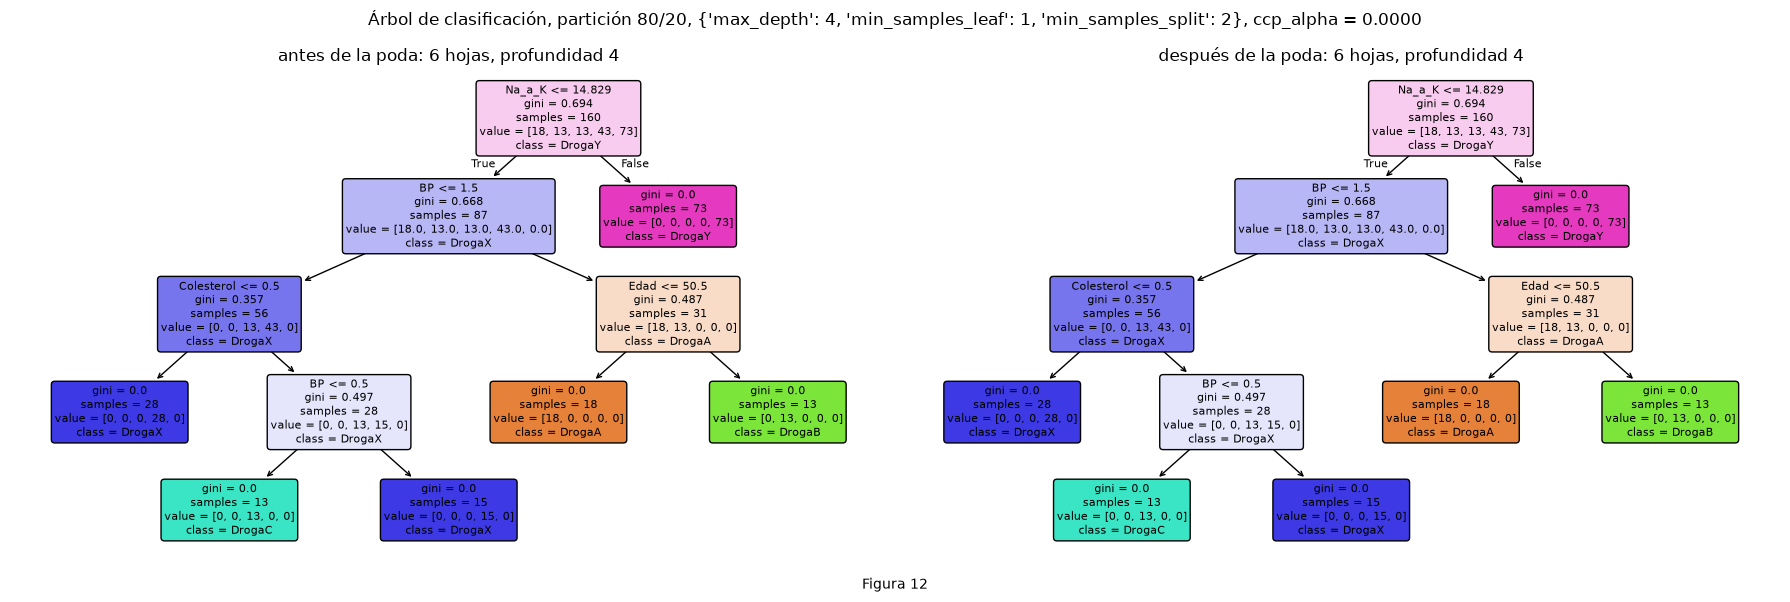

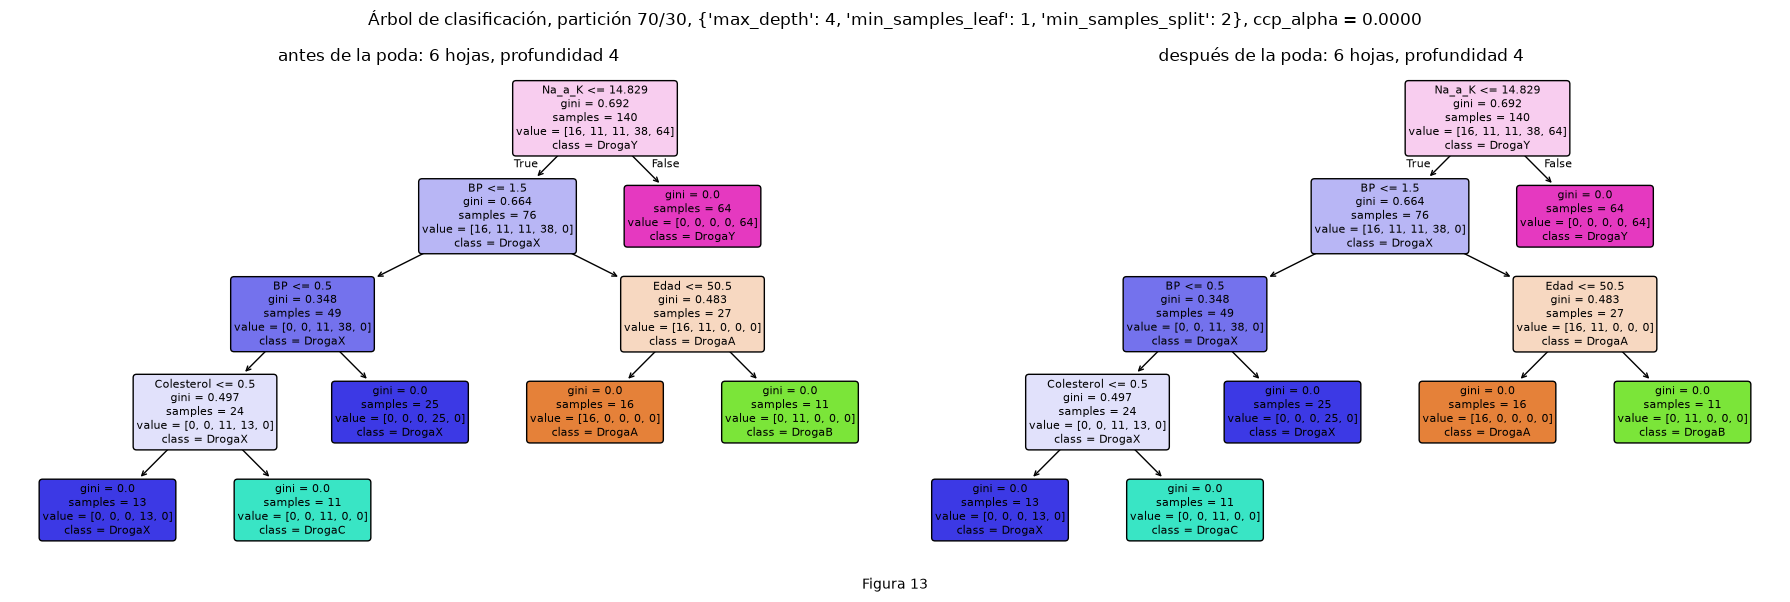

,,Precision macro,Recall macro,Accuracy
Modelo,Partición,,,
Árbol antes de podar,80/20,1.0,1.0,1.0
Árbol podado,80/20,1.0,1.0,1.0
Árbol antes de podar,70/30,1.0,1.0,1.0
Árbol podado,70/30,1.0,1.0,1.0


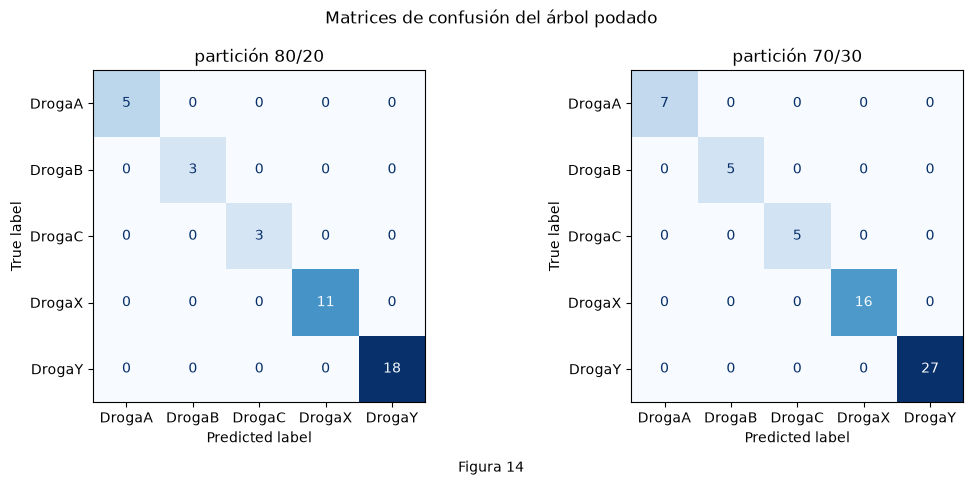

In [26]:
# Grafico el árbol antes y después de la post-poda y calculo las métricas en ambos test
resultados = []      # guardo una fila por modelo y partición para las Actividades 4 a 7
pred_arbol = {}
for i, nombre in enumerate(part_B, 1):
    Xtrn, Xtst = datos_arbol[nombre]
    ytrn, ytst = part_B[nombre][2], part_B[nombre][3]
    params = grid_arbol[nombre].best_params_
    antes = DecisionTreeClassifier(random_state=SEED, **params).fit(Xtrn, ytrn)
    despues = DecisionTreeClassifier(random_state=SEED, **params, ccp_alpha=alpha_sel[nombre]).fit(Xtrn, ytrn)
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    for ax, arbol, titulo in zip(axes, [antes, despues], ["antes de la poda", "después de la poda"]):
        plot_tree(arbol, feature_names=list(Xtrn.columns), class_names=list(arbol.classes_), filled=True, rounded=True,
                  fontsize=8, ax=ax)
        ax.set_title(f"{titulo}: {arbol.get_n_leaves()} hojas, profundidad {arbol.get_depth()}")
    plt.suptitle(f"Árbol de clasificación, partición {nombre}, {params}, ccp_alpha = {alpha_sel[nombre]:.4f}")
    numerar(11 + i)
    plt.show()
    pred_arbol[nombre] = despues.predict(Xtst)
    resultados.append(fila(nombre, "Árbol antes de podar", ytst, antes.predict(Xtst)))
    resultados.append(fila(nombre, "Árbol podado", ytst, pred_arbol[nombre]))

display(pd.DataFrame(resultados).set_index(["Modelo", "Partición"]).round(3))
plot_cms(pred_arbol, "Matrices de confusión del árbol podado", 14)

Figuras 12 y 13. Los dos árboles tienen 6 hojas, las mismas reglas y umbrales en unidades originales. Solo cambia el orden de los cortes en la rama izquierda. La raíz divide por Na_a_K <= 14.829: la rama derecha es pura de DrogaY (73 y 64 casos) y el umbral queda entre el máximo de las otras clases (14.64) y el mínimo de DrogaY (15.02). En la rama izquierda, BP separa los casos. Con BP Alto, Edad <= 50.5 separa DrogaA de DrogaB. Con BP Bajo o Normal, Colesterol y BP separan DrogaC de DrogaX (DrogaC aparece solo con BP Bajo y Colesterol Alto). Las reglas coinciden con las tablas de la Figura 10 y la hipótesis se cumple.

Test: Precision macro, Recall macro y Accuracy valen 1.000 en ambas particiones, antes y después de podar. La Figura 14 muestra matrices sin errores (80/20: 5, 3, 3, 11 y 18 casos en la diagonal; 70/30: 7, 5, 5, 16 y 27). Con 40 y 60 observaciones y 3 a 5 casos en las clases chicas, un 1.0 es evidencia limitada.

In [27]:
# Armo una tabla con la importancia de cada variable en el árbol podado de cada partición
for nombre, (Xtrn, Xtst) in datos_arbol.items():
    podado = DecisionTreeClassifier(random_state=SEED, **grid_arbol[nombre].best_params_,
                                    ccp_alpha=alpha_sel[nombre]).fit(Xtrn, part_B[nombre][2])
    print(f"Partición {nombre}")
    display(pd.DataFrame({"features": Xtrn.columns, "importances": podado.feature_importances_})
            .sort_values(by="importances", ascending=False).round(3))

Partición 80/20


,features,importances
4,Na_a_K,0.476
1,BP,0.333
3,Edad,0.136
2,Colesterol,0.054
0,Sexo,0.000


Partición 70/30


,features,importances
4,Na_a_K,0.479
1,BP,0.263
3,Edad,0.135
2,Colesterol,0.123
0,Sexo,0.000


Importancias. Na_a_K es la más importante en ambas particiones (0.476 y 0.479), seguida por BP (0.333 y 0.263) y Edad (0.136 y 0.135). Colesterol pesa 0.054 y 0.123. Sexo vale 0: no participa en ningún corte. Confirma la hipótesis y las reglas de las Figuras 12 y 13.

## Actividad 5. Bayes Ingenuo

Discretizamos Edad y Na_a_K con KBinsDiscretizer por cuantiles (3 y 5 intervalos), codificamos con one-hot y aplicamos MultinomialNB. Como alternativa usamos GaussianNB sobre datos estandarizados. El discretizador se ajusta solo con train. Elegimos el mejor de los tres por validación cruzada de 5 folds, sin mirar el test.

Hipótesis: 5 intervalos rinde mejor que 3. GaussianNB podría rendir peor, porque Na_a_K de DrogaY es asimétrica (Figura 10).

80/20 bordes de los 5 intervalos (Edad, Na_a_K): [[15.0, 28.0, 39.0, 50.0, 61.5, 74.0], [6.3, 9.9, 12.8, 16.1, 22.8, 38.2]]


70/30 bordes de los 5 intervalos (Edad, Na_a_K): [[15.0, 27.0, 38.5, 50.0, 61.0, 74.0], [6.3, 9.8, 12.5, 16.3, 22.9, 38.2]]


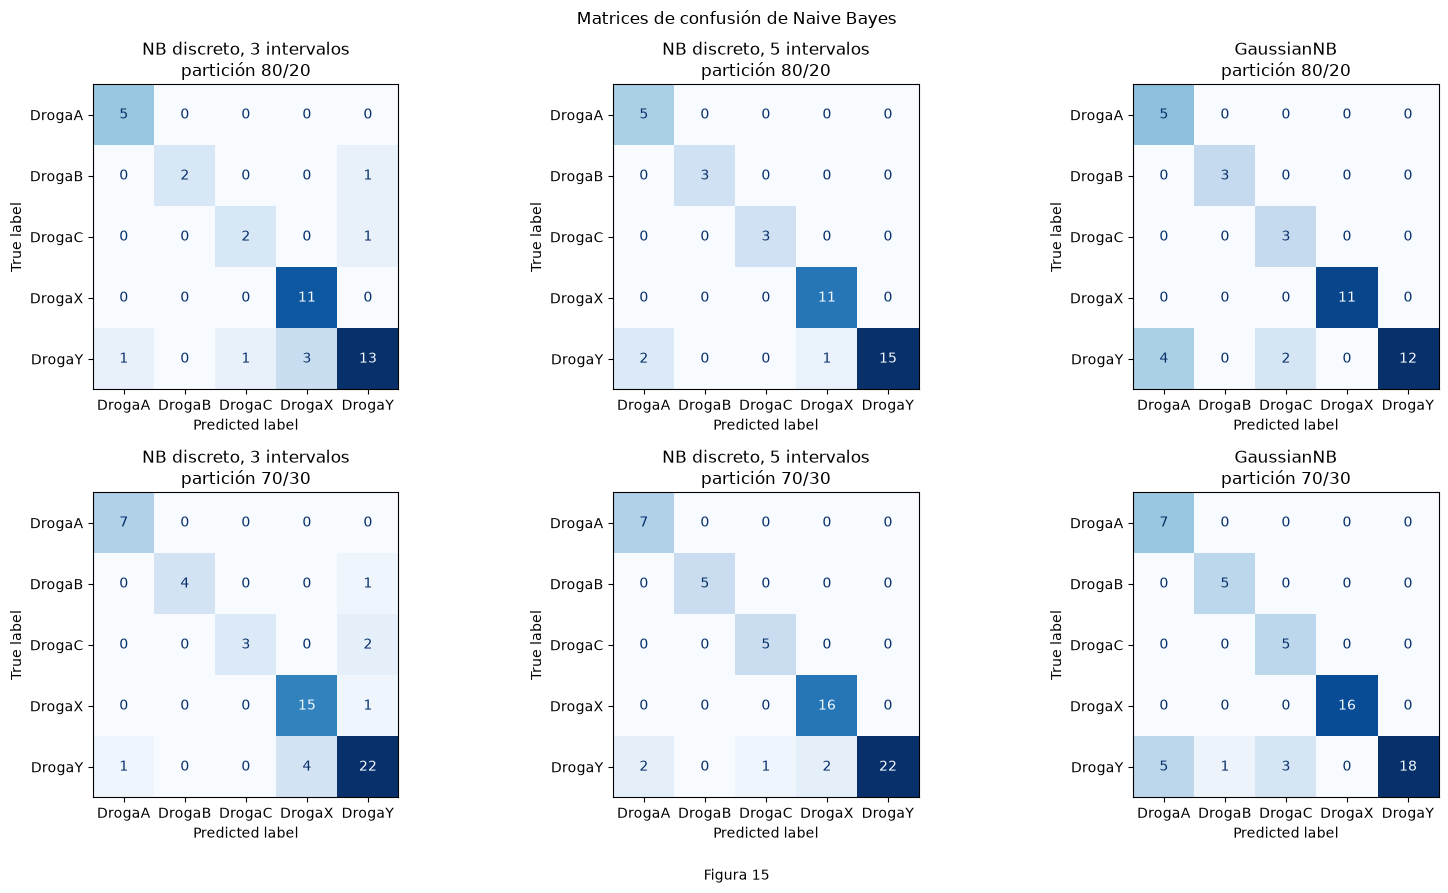

Precision macro  Recall macro  Accuracy  \
Partición Modelo                                                               
80/20     NB discreto, 3 intervalos            0.830         0.811     0.825   
          NB discreto, 5 intervalos            0.926         0.967     0.925   
          GaussianNB                           0.831         0.933     0.850   
70/30     NB discreto, 3 intervalos            0.902         0.830     0.850   
          NB discreto, 5 intervalos            0.900         0.963     0.917   
          GaussianNB                           0.808         0.933     0.850   

                                     F1 macro CV (train)  
Partición Modelo                                          
80/20     NB discreto, 3 intervalos                0.691  
          NB discreto, 5 intervalos                0.811  
          GaussianNB                               0.813  
70/30     NB discreto, 3 intervalos                0.639  
          NB discreto, 5 intervalos                0.766  
          GaussianNB                               0.843

Mejor Naive Bayes por validación cruzada en train: {'80/20': 'GaussianNB', '70/30': 'GaussianNB'}


In [28]:
# Defino el Naive Bayes discretizado: KBinsDiscretizer por cuantiles y MultinomialNB
def nb_discreto(bins):
    return make_pipeline(
        make_column_transformer(
            (KBinsDiscretizer(n_bins=bins, encode="onehot", strategy="quantile"), ["Edad", "Na_a_K"]),
            (OneHotEncoder(), ["Sexo", "BP", "Colesterol"])),
        MultinomialNB())

# Entreno los tres Naive Bayes y los evalúo en ambos test
etiquetas_nb = ["NB discreto, 3 intervalos", "NB discreto, 5 intervalos", "GaussianNB"]
mejor_nb = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for fila_ax, nombre in zip(axes, part_B):
    Xtrn_raw, Xtst_raw, ytrn, ytst = part_B[nombre]
    Xtrn, Xtst = datos_B[nombre]
    modelos = [nb_discreto(3), nb_discreto(5), GaussianNB()]
    datos_nb = [(Xtrn_raw, Xtst_raw), (Xtrn_raw, Xtst_raw), (Xtrn, Xtst)]
    mejor_f1 = 0
    for ax, etiqueta, modelo, (Xa, Xb) in zip(fila_ax, etiquetas_nb, modelos, datos_nb):
        f1_cv = cross_val_score(modelo, Xa, ytrn, cv=5, scoring="f1_macro").mean()
        pred = modelo.fit(Xa, ytrn).predict(Xb)
        resultado = fila(nombre, etiqueta, ytst, pred)
        resultado["F1 macro CV (train)"] = f1_cv
        resultados.append(resultado)
        if f1_cv > mejor_f1:
            mejor_f1, mejor_nb[nombre] = f1_cv, etiqueta
        ConfusionMatrixDisplay.from_predictions(ytst, pred, ax=ax, cmap="Blues", colorbar=False)
        ax.set_title(f"{etiqueta}\npartición {nombre}")
    kb = modelos[1][0].named_transformers_["kbinsdiscretizer"]   # bordes de los intervalos del NB de 5 bins, para interpretar
    print(nombre, "bordes de los 5 intervalos (Edad, Na_a_K):", [np.round(b, 1).tolist() for b in kb.bin_edges_])
plt.suptitle("Matrices de confusión de Naive Bayes")
numerar(15)
plt.show()

tabla = pd.DataFrame(resultados)
display(tabla[tabla["Modelo"].isin(etiquetas_nb)].set_index(["Partición", "Modelo"]).round(3))
print("Mejor Naive Bayes por validación cruzada en train:", mejor_nb)

Bordes de los 5 intervalos (80/20): Edad [15, 28, 39, 50, 61.5, 74] y Na_a_K [6.3, 9.9, 12.8, 16.1, 22.8, 38.2]. El intervalo de Na_a_K entre 12.8 y 16.1 mezcla DrogaY (desde 15.02) con otras clases (hasta 14.64). El corte del árbol (14.829) no existe en esta discretización.

Resultados (F1 macro de validación en train y métricas en test):

- 3 intervalos: F1 de validación 0.691 (80/20) y 0.639 (70/30). Accuracy de test 0.825 y 0.850.
- 5 intervalos: F1 de validación 0.811 y 0.766. Accuracy de test 0.925 y 0.917. Recall macro 0.967 y 0.963.
- GaussianNB: F1 de validación 0.813 y 0.843. Accuracy de test 0.850 en ambas. Precision macro 0.831 y 0.808.

Pasar de 3 a 5 intervalos mejora el F1 de validación, como esperábamos. GaussianNB queda primero en validación en las dos particiones (ventaja mínima en el 80/20: 0.813 contra 0.811), pero en test rinde peor en Accuracy que 5 intervalos. La hipótesis sobre GaussianNB se cumple solo en parte. Elegimos GaussianNB, porque elegir con el test no corresponde.

Figura 15. Los errores se concentran en DrogaY. Con GaussianNB, 6 de 18 casos de DrogaY se clasifican mal en el 80/20 (4 como DrogaA y 2 como DrogaC) y 9 de 27 en el 70/30. Con 5 intervalos bajan a 3 y 5. Con GaussianNB y con 5 intervalos las otras clases no tienen errores propios. Con 3 intervalos también fallan DrogaB y DrogaC.

## Actividad 6. k-NN

Grilla: n_neighbors en 1, 3, 5, 7 y 9, y metric en euclidean y manhattan (10 combinaciones). Validación cruzada de 5 folds sobre train con F1 macro. Usamos datos estandarizados para que Edad y Na_a_K pesen parecido en la distancia. La clase más chica tiene 13 casos en el train del 80/20 y 11 en el del 70/30, y el k máximo (9) queda por debajo.

Hipótesis: k-NN separa bien a DrogaY por Na_a_K, pero trata BP y Colesterol como números ordinales. Esperamos un resultado por debajo del árbol.

In [29]:
# Busco k y la métrica de k-NN con GridSearchCV sobre datos estandarizados
# Defino la grilla; el TP pide metric: euclidean o manhattan
param_grid_knn = {"n_neighbors": [1, 3, 5, 7, 9], "metric": ["euclidean", "manhattan"]}
grid_knn = {}
pred_knn = {}
for nombre in part_B:
    Xtrn, Xtst = datos_B[nombre]
    ytrn, ytst = part_B[nombre][2], part_B[nombre][3]
    g = GridSearchCV(KNeighborsClassifier(), param_grid_knn, cv=5, scoring="f1_macro").fit(Xtrn, ytrn)
    grid_knn[nombre] = g
    pred_knn[nombre] = g.predict(Xtst)
    resultados.append(fila(nombre, "k-NN", ytst, pred_knn[nombre]))
    print(f"Partición {nombre}: mejor = {g.best_params_}, F1 macro CV = {g.best_score_:.3f}, "
          f"clase más chica en train = {ytrn.value_counts().min()}")
    results = pd.DataFrame(g.cv_results_)
    display(results.sort_values("rank_test_score")[["rank_test_score", "param_n_neighbors", "param_metric", "mean_test_score"]]
            .rename(columns={"mean_test_score": "F1 macro CV"}).round(3))
    print(classification_report(ytst, pred_knn[nombre]))

Partición 80/20: mejor = {'metric': 'euclidean', 'n_neighbors': 1}, F1 macro CV = 0.862, clase más chica en train = 13


,rank_test_score,param_n_neighbors,param_metric,F1 macro CV
0,1,1,euclidean,0.862
9,2,9,manhattan,0.854
5,3,1,manhattan,0.854
1,4,3,euclidean,0.842
6,5,3,manhattan,0.840
7,6,5,manhattan,0.839
2,7,5,euclidean,0.802
8,8,7,manhattan,0.799
4,9,9,euclidean,0.777
3,10,7,euclidean,0.757


              precision    recall  f1-score   support

      DrogaA       0.80      0.80      0.80         5
      DrogaB       0.75      1.00      0.86         3
      DrogaC       0.75      1.00      0.86         3
      DrogaX       0.83      0.91      0.87        11
      DrogaY       0.93      0.78      0.85        18

    accuracy                           0.85        40
   macro avg       0.81      0.90      0.85        40
weighted avg       0.86      0.85      0.85        40



Partición 70/30: mejor = {'metric': 'manhattan', 'n_neighbors': 9}, F1 macro CV = 0.818, clase más chica en train = 11


,rank_test_score,param_n_neighbors,param_metric,F1 macro CV
9,1,9,manhattan,0.818
7,2,5,manhattan,0.787
0,3,1,euclidean,0.777
4,4,9,euclidean,0.767
2,5,5,euclidean,0.763
8,6,7,manhattan,0.750
5,7,1,manhattan,0.741
6,8,3,manhattan,0.729
3,9,7,euclidean,0.718
1,10,3,euclidean,0.699


              precision    recall  f1-score   support

      DrogaA       0.88      1.00      0.93         7
      DrogaB       1.00      1.00      1.00         5
      DrogaC       1.00      0.80      0.89         5
      DrogaX       0.84      1.00      0.91        16
      DrogaY       0.96      0.85      0.90        27

    accuracy                           0.92        60
   macro avg       0.94      0.93      0.93        60
weighted avg       0.92      0.92      0.92        60



,Modelo,Precision macro,Recall macro,Accuracy
Partición,,,,
80/20,k-NN,0.813,0.897,0.850
70/30,k-NN,0.935,0.930,0.917


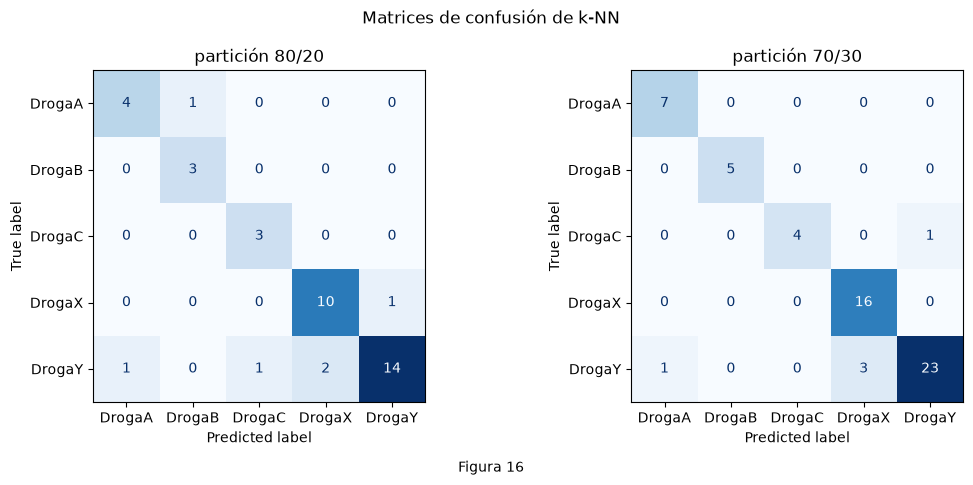

In [30]:
# Muestro las métricas de k-NN y sus matrices de confusión
display(pd.DataFrame(resultados).query('Modelo == "k-NN"').set_index("Partición").dropna(axis=1).round(3))
plot_cms(pred_knn, "Matrices de confusión de k-NN", 16)

Mejor combinación: euclidean con k=1 en el 80/20 (F1 de validación 0.862) y manhattan con k=9 en el 70/30 (0.818). Manhattan supera a euclidean en 3 de 5 valores de k en el 80/20 y en 4 en el 70/30: ninguna métrica es claramente mejor. La elección de k depende de la partición.

Test: 80/20 con Precision macro 0.813, Recall macro 0.897 y Accuracy 0.850. 70/30 con 0.935, 0.930 y 0.917.

Figura 16. Errores del 80/20: DrogaY como DrogaX (2), DrogaA (1) y DrogaC (1), un DrogaX como DrogaY y un DrogaA como DrogaB. Errores del 70/30: DrogaY como DrogaX (3) y DrogaA (1), y un DrogaC como DrogaY. DrogaB no tiene errores de Recall. La hipótesis se cumple: k-NN queda por debajo del árbol (Accuracy 0.850 y 0.917 contra 1.0).

## Actividad 7. Comparación de modelos

La tabla reúne el árbol podado (igual al no podado), GaussianNB (elegido por validación cruzada) y el k-NN de la Actividad 6.

In [31]:
# Armo la tabla comparativa con el mejor modelo de cada algoritmo
# Tabla comparativa: mejor modelo de cada algoritmo
tabla = pd.DataFrame(resultados)
comparacion = pd.DataFrame()
for nombre in part_B:
    elegidos = ["Árbol podado", mejor_nb[nombre], "k-NN"]
    comparacion = pd.concat([comparacion, tabla[(tabla["Partición"] == nombre) & tabla["Modelo"].isin(elegidos)]])
display(comparacion.set_index(["Partición", "Modelo"])[["Precision macro", "Recall macro", "Accuracy"]].round(3))

Precision macro  Recall macro  Accuracy
Partición Modelo                                               
80/20     Árbol podado            1.000         1.000     1.000
          GaussianNB              0.831         0.933     0.850
          k-NN                    0.813         0.897     0.850
70/30     Árbol podado            1.000         1.000     1.000
          GaussianNB              0.808         0.933     0.850
          k-NN                    0.935         0.930     0.917

Resultados (Precision macro, Recall macro y Accuracy):

- Árbol: 1.000, 1.000 y 1.000 en ambos test.
- k-NN: 0.813, 0.897 y 0.850 (80/20), y 0.935, 0.930 y 0.917 (70/30).
- GaussianNB: 0.831, 0.933 y 0.850 (80/20), y 0.808, 0.933 y 0.850 (70/30).

Elegimos el árbol de decisión:

- Tiene las mejores métricas y es el único sin errores en las matrices de confusión.
- Es interpretable: 6 reglas con 4 atributos (Na_a_K, BP, Colesterol y Edad), con umbrales en unidades originales (Figuras 12 y 13) y coherentes con el EDA.
- No necesita estandarizar ni winsorizar: se entrena con los datos originales.
- k-NN no entrega reglas y su F1 de validación (0.862 y 0.818) es menor que el del árbol (0.977 y 0.965).
- Bayes Ingenuo es simple y rápido, pero queda por debajo del árbol.

Limitaciones: los test tienen 40 y 60 observaciones, con 3 a 5 casos en las clases chicas, así que un 1.0 no garantiza lo mismo con datos nuevos. Los árboles de las dos particiones usan el mismo umbral de Na_a_K (14.829) y las mismas variables, lo que sugiere reglas estables.

# Conclusiones

Parte A (regresión):

- Eliminamos 3 filas anómalas de Profit y 1 fila duplicada.
- El mejor árbol (max_depth=10, min_samples_leaf=5 y min_samples_split=2) logra MAE de 1098.9 y 942.6, y RMSE de 3496.1 y 2929.1 en los test 80/20 y 70/30.
- RyD_Spend domina los primeros cortes, en coincidencia con su correlación de 0.999 con Profit. Administration (0.745) casi no interviene.
- Las importancias lo confirman: RyD_Spend suma 0.989 y 0.991 en los dos árboles, y las variables de State valen 0.

Parte B (clasificación):

- Droga está desbalanceada (la clase mayoritaria es 5.69 veces la minoritaria). Estratificamos las particiones y usamos métricas macro.
- Na_a_K separa a DrogaY. BP, Colesterol y Edad separan las demás clases. El árbol de 6 hojas, entrenado con los datos originales, alcanza 1.000 en Precision macro, Recall macro y Accuracy en ambos test. Su corte principal es Na_a_K <= 14.829.
- Las importancias lo confirman: Na_a_K pesa 0.476 y 0.479, BP 0.333 y 0.263, y Sexo no participa (0).
- La validación cruzada eligió ccp_alpha=0.0: todo alpha positivo bajó el F1, y el árbol antes y después de podar es el mismo.
- En Bayes Ingenuo, 5 intervalos rinden mejor que 3. GaussianNB ganó la validación cruzada y alcanzó Accuracy de 0.850 en ambos test. Con 5 intervalos fue 0.925 y 0.917.
- k-NN alcanzó Accuracy de 0.850 (euclidean, k=1) y 0.917 (manhattan, k=9). La métrica y k cambiaron con la partición.
- Elegimos el árbol de decisión por sus métricas y por la claridad de sus reglas.

Balance de hipótesis:

- Se cumplieron: Profit sube con RyD_Spend y MarketingSpend, y esas dos están correlacionadas entre sí; State influye poco; el primer corte del árbol de regresión es por RyD_Spend; Na_a_K separa a DrogaY; BP y Colesterol aportan reglas y Sexo no influye; el árbol de clasificación es chico y su raíz usa Na_a_K; 5 intervalos rinden mejor que 3; k-NN queda por debajo del árbol.
- Se cumplieron en parte: Administration tiene correlación moderada (0.74) y no débil; GaussianNB rinde igual o mejor que 5 intervalos en validación, pero peor en test.
- No prevista: Edad ayuda a distinguir DrogaA de DrogaB.

Limitaciones: los test son chicos y la selección de hiperparámetros usa validación cruzada sobre train, con una sola semilla (63).